# VoiceLab starter notebook
AIML ZG520. Keep all outputs. Commit as you work (`!python voicelab.py save "message"`). Parts marked [Critical] must be your own code.

First time only: upload the kit and your `<ROLLNO>_config.json`, then run `!python voicelab.py setup`. Check progress any time with `!python voicelab.py progress`.

In [18]:
# Colab: upload <ROLLNO>_config.json (setup copies it to config.json), voicelab_utils.py and your data/ folder first
import numpy as np, matplotlib.pyplot as plt
from voicelab_utils import *
cfg = load_config('config.json')
set_seed(cfg)
res = Results('results.json')
print(cfg['vocab'])
print(cfg['sentences_spoken'])

['bed', 'bad', 'sink', 'think', 'mat', 'net', 'rice', 'lice', 'pan', 'sheep']
['nine chargers cost five hundred rupees in lucknow', 'remind me to meet anirudh in kochi on thursday', 'call pooja on tuesday morning about the keyboards', 'book three tickets to nagpur for shruti']


## Part 0: Dataset and audit

Three recording blocks: words (30 clips), sentences (4 clips) and room noise (about 11 s). Each block starts with your spoken code, then pauses of 2 s between items.

1. Run the next cell (or `python voicelab.py script`) to print your read-aloud script.
2. Record the three blocks. Save the originals as `data/original/words_block.*`, `sentences_block.*` and `noise_block.*`.
3. Run the cell after that. It converts to 16 kHz mono, splits the clips, audits them and checks your spoken code. Read what it prints: `CHECK` lines name clips to listen to, and `STOPPED` means a block must be recorded again with longer pauses.

In [19]:
recording_script(cfg)

BLOCK 1: WORDS  (record as data/original/words_block.wav)
Silence 1 s, say the code, pause 2 s. Then each line below: say the word once, pause 2 s.
  CODE: 5 5 1 8 3 8
  bed   (repetition 0)
  bed   (repetition 1)
  bed   (repetition 2)
  bad   (repetition 0)
  bad   (repetition 1)
  bad   (repetition 2)
  sink   (repetition 0)
  sink   (repetition 1)
  sink   (repetition 2)
  think   (repetition 0)
  think   (repetition 1)
  think   (repetition 2)
  mat   (repetition 0)
  mat   (repetition 1)
  mat   (repetition 2)
  net   (repetition 0)
  net   (repetition 1)
  net   (repetition 2)
  rice   (repetition 0)
  rice   (repetition 1)
  rice   (repetition 2)
  lice   (repetition 0)
  lice   (repetition 1)
  lice   (repetition 2)
  pan   (repetition 0)
  pan   (repetition 1)
  pan   (repetition 2)
  sheep   (repetition 0)
  sheep   (repetition 1)
  sheep   (repetition 2)

BLOCK 2: SENTENCES  (record as data/original/sentences_block.wav)
Silence 1 s, say the code, pause 2 s. Then each senten

'BLOCK 1: WORDS  (record as data/original/words_block.wav)\nSilence 1 s, say the code, pause 2 s. Then each line below: say the word once, pause 2 s.\n  CODE: 5 5 1 8 3 8\n  bed   (repetition 0)\n  bed   (repetition 1)\n  bed   (repetition 2)\n  bad   (repetition 0)\n  bad   (repetition 1)\n  bad   (repetition 2)\n  sink   (repetition 0)\n  sink   (repetition 1)\n  sink   (repetition 2)\n  think   (repetition 0)\n  think   (repetition 1)\n  think   (repetition 2)\n  mat   (repetition 0)\n  mat   (repetition 1)\n  mat   (repetition 2)\n  net   (repetition 0)\n  net   (repetition 1)\n  net   (repetition 2)\n  rice   (repetition 0)\n  rice   (repetition 1)\n  rice   (repetition 2)\n  lice   (repetition 0)\n  lice   (repetition 1)\n  lice   (repetition 2)\n  pan   (repetition 0)\n  pan   (repetition 1)\n  pan   (repetition 2)\n  sheep   (repetition 0)\n  sheep   (repetition 1)\n  sheep   (repetition 2)\n\nBLOCK 2: SENTENCES  (record as data/original/sentences_block.wav)\nSilence 1 s, say t

In [20]:
# Whole of Part 0 in one command. Run it in a terminal first (it also checks your spoken code with Whisper);
# the options below only repeat the audit when the clips already exist.
!python voicelab.py data --skip-existing --no-whisper

Blocks already converted: skipping conversion.
words: clips already present, skipping the split.
sentences: clips already present, skipping the split.
noise: clips already present, skipping the split.

--- audit
35 files audited (details in data/audit_report.csv).
  no clip was flagged

Spoken-code check skipped (--no-whisper).

PLEASE CONFIRM YOUR RECORDINGS
No clip or block was flagged. Still, listen to a few clips to be sure.

  All recordings OK?    -> continue:  python voicelab.py save "Part 0 data"
                                      python voicelab.py precompute
  Something not OK?     -> record that block again (say every item, pause at least 2 seconds
                           after each), save it over the file in data/original/ and rerun:
                           python voicelab.py data
  A clip that is only a little long, with a breath or extra silence at its edges, is fine.


In [21]:
rows = audit_folder('data')
print_table([r for r in rows if r['clipping_pct'] > 0.5 or r['snr_db'] < 15][:20])  # clips worth a second look

file | duration_s | peak | clipping_pct | snr_db | silence_frac
room_noise.wav | 15.71 | 0.052 | 0.0 | 4.5 | 1.0


## Part 1: Signal analysis and features
TODO: hand DFT (markdown cell), plot a sentence, [Critical] MFCC pipeline, [Critical] F0 by autocorrelation on your sentences.

In [22]:
# [starter] plumbing, not counted as your own code
# Setup for Part 1 (plumbing only). Your front-end settings are in cfg['front_end'].
import glob
fe = cfg['front_end']
words = {w: [f'data/words/{w}_{r}.wav' for r in range(3)] for w in cfg['vocab']}   # 3 repetitions of each word
first_clip = sorted(glob.glob('data/words/*.wav'))[0]                               # the clip for 'mfcc_sum_first_clip'
print(fe)
print('first clip:', first_clip)

{'sr': 16000, 'frame_ms': 25, 'hop_ms': 10, 'window': 'hann', 'n_mels': 26, 'n_mfcc': 12, 'preemph': 0.95, 'lifter': 0, 'delta_N': 2}
first clip: data/words/bad_0.wav


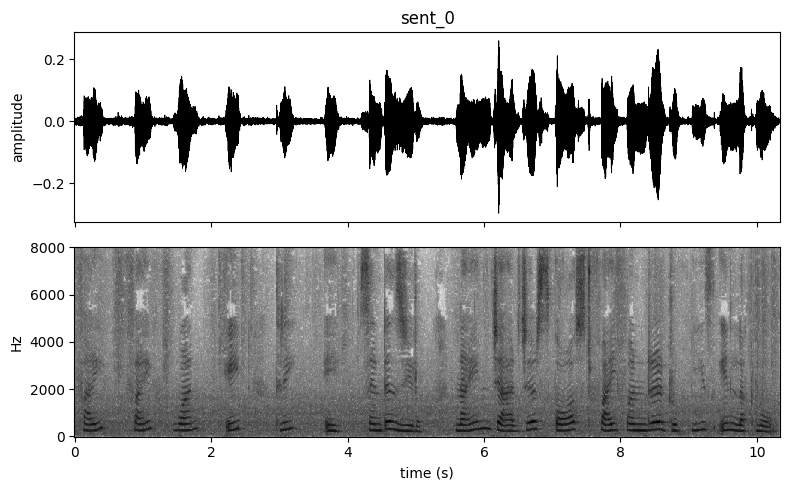

In [23]:
# [starter] plumbing, not counted as your own code
# Spectrogram of a sentence at your sampling rate (a quick helper; use your own STFT if you prefer).
x, fs = load_wav('data/sentences/sent_0.wav', sr=fe['sr'])
plot_wave_spec(x, fs, title='sent_0')
savefig('p1_sent0_spectrogram')      # figures/p1_sent0_spectrogram.png goes into your report
plt.show()

In [24]:
# [Critical] MFCC pipeline: write it yourself with NumPy/SciPy (no librosa.feature.mfcc, no filterbank helper).
# def my_mfcc(x, fs, fe): ...
# mine = my_mfcc(*load_wav(first_clip, sr=fe['sr']), fe)          # shape (frames, n_mfcc)
# Verification only: compare with librosa configured identically, then report the maximum difference per coefficient.
# compare('MFCC vs librosa', mine, librosa_mfcc)
# res.set('mfcc_sum_first_clip', mine.sum())

In [40]:

import numpy as np
from scipy.fft import dct

def my_mfcc(x, fs, fe):
    # 1. Convert audio to floating point
    x = np.asarray(x, dtype=float)

    # 2. Pre-emphasis
    x = np.append(x[0], x[1:] - fe['preemph'] * x[:-1])

    # 3. Frame the signal
    frame_length = int(fe['frame_ms'] * fs / 1000)
    hop_length = int(fe['hop_ms'] * fs / 1000)

    frames = np.array([
        x[i:i + frame_length]
        for i in range(0, len(x) - frame_length + 1, hop_length)
    ])

    # 4. Apply Hann window
    window = np.hanning(frame_length)
    frames = frames * window

    # 5. Calculate power spectrum
    n_fft = 512
    spectrum = np.abs(np.fft.rfft(frames, n=n_fft)) ** 2

    # 6. Create Mel filter bank manually
    def hz_to_mel(hz):
        return 2595 * np.log10(1 + hz / 700)

    def mel_to_hz(mel):
        return 700 * (10 ** (mel / 2595) - 1)

    low_mel = hz_to_mel(0)
    high_mel = hz_to_mel(fs / 2)
    mel_points = np.linspace(low_mel, high_mel, fe['n_mels'] + 2)
    hz_points = mel_to_hz(mel_points)

    bins = np.floor((n_fft + 1) * hz_points / fs).astype(int)
    filters = np.zeros((fe['n_mels'], n_fft // 2 + 1))

    for m in range(1, fe['n_mels'] + 1):
        left = bins[m - 1]
        center = bins[m]
        right = bins[m + 1]

        for k in range(left, center):
            if center > left:
                filters[m - 1, k] = (k - left) / (center - left)

        for k in range(center, right):
            if right > center:
                filters[m - 1, k] = (right - k) / (right - center)

    # 7. Apply Mel filters and logarithm
    mel_energy = np.dot(spectrum, filters.T)
    log_mel = np.log(np.maximum(mel_energy, 1e-10))

    # 8. Apply Discrete Cosine Transform
    mfcc = dct(log_mel, type=2, axis=1, norm='ortho')
    mfcc = mfcc[:, :fe['n_mfcc']]

    # 9. Apply optional liftering
    if fe['lifter'] > 0:
        n = np.arange(fe['n_mfcc'])
        lift = 1 + (fe['lifter'] / 2) * np.sin(np.pi * n / fe['lifter'])
        mfcc = mfcc * lift

    return mfcc


# Calculate MFCC for your first word recording
audio, sample_rate = load_wav(first_clip, sr=fe['sr'])
mine = my_mfcc(audio, sample_rate, fe)

print("MFCC shape:", mine.shape)
print("MFCC sum:", mine.sum())

# Save the required result
res.set('mfcc_sum_first_clip', mine.sum())


MFCC shape: (56, 12)
MFCC sum: -2407.322836948214


In [41]:
print(res.data)

{'mfcc_sum_first_clip': -2407.322836948214}


In [42]:
!python voicelab.py progress

VoiceLab progress  (roll 2025AE05100)
Submission: 28 November (6 days left)
This shows whether the evidence is present, not whether your work is correct.
[x] evidence found   [ ] not yet   [-] you confirm this yourself (not counted)

[x] Set up                                     3/3  done
      [x] your configuration file is present and readable (do not edit it)
      [x] notebook is renamed to voicelab.ipynb
      [x] git repository exists with at least one commit

[x] Part 0. Dataset                            7/7  done
      [x] originals kept in data/original/ (3 files: words, sentences, room noise)
      [x] 3 converted block files in data/blocks/ (16 kHz, mono, 16-bit)
      [x] 30 word clips in data/words/ named word_rep.wav
      [x] 4 sentence clips sent_0.wav to sent_3.wav in data/sentences/
      [x] room noise clip data/noise/room_noise.wav (at least 8 s)
      [x] every clip is 16 kHz, mono, 16-bit
      [x] split reports written (read them for WARNING lines and listen to

In [25]:
# [Critical] F0 by autocorrelation on your sentences: write it yourself.
# savefig('p1_f0_sent0')

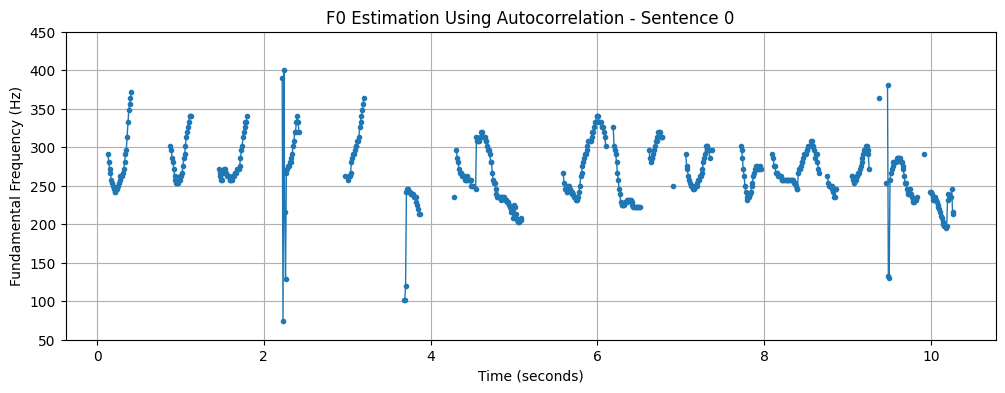

Total frames: 1030
Voiced frames: 546
Average F0: 267.1110791401748 Hz
Minimum F0: 74.07407407407408 Hz
Maximum F0: 400.0 Hz


In [44]:

import numpy as np
import matplotlib.pyplot as plt

def estimate_f0_autocorrelation(x, fs):

    # Convert audio to NumPy array
    x = np.asarray(x, dtype=float)

    # Remove DC component
    x = x - np.mean(x)

    # Frame settings
    frame_length = int(0.040 * fs)  # 40 milliseconds
    hop_length = int(0.010 * fs)    # 10 milliseconds

    # Expected human voice pitch range
    min_f0 = 70
    max_f0 = 400

    min_lag = int(fs / max_f0)
    max_lag = int(fs / min_f0)

    f0_values = []
    times = []

    # Process audio frame by frame
    for start in range(0, len(x) - frame_length + 1, hop_length):

        frame = x[start:start + frame_length]

        # Apply Hann window
        frame = frame * np.hanning(frame_length)

        # Reject silent frames
        if np.sqrt(np.mean(frame ** 2)) < 0.005:
            f0_values.append(np.nan)
            times.append((start + frame_length / 2) / fs)
            continue

        # Calculate autocorrelation
        correlation = np.correlate(frame, frame, mode='full')
        correlation = correlation[len(frame)-1:]

        # Search for the best pitch lag
        search = correlation[min_lag:max_lag + 1]

        if len(search) == 0 or np.max(search) <= 0:
            f0_values.append(np.nan)

        else:
            best_index = np.argmax(search)
            best_lag = min_lag + best_index

            # Reject unreliable pitch estimates
            if search[best_index] / (correlation[0] + 1e-10) < 0.30:
                f0_values.append(np.nan)
            else:
                f0_values.append(fs / best_lag)

        times.append((start + frame_length / 2) / fs)

    return np.array(times), np.array(f0_values)


# Load first sentence recording
x, fs = load_wav('data/sentences/sent_0.wav', sr=fe['sr'])

# Estimate fundamental frequency
times, f0 = estimate_f0_autocorrelation(x, fs)

# Plot F0 contour
plt.figure(figsize=(12, 4))
plt.plot(times, f0, marker='.', linewidth=1)

plt.xlabel('Time (seconds)')
plt.ylabel('Fundamental Frequency (Hz)')
plt.title('F0 Estimation Using Autocorrelation - Sentence 0')
plt.ylim(50, 450)
plt.grid(True)

# Save figure for report
savefig('p1_f0_sent0')
plt.show()

# Display pitch statistics
valid_f0 = f0[~np.isnan(f0)]

print("Total frames:", len(f0))
print("Voiced frames:", len(valid_f0))

if len(valid_f0) > 0:
    print("Average F0:", np.mean(valid_f0), "Hz")
    print("Minimum F0:", np.min(valid_f0), "Hz")
    print("Maximum F0:", np.max(valid_f0), "Hz")
else:
    print("No reliable voiced frames detected.")


In [26]:
# Save each figure for the report with savefig('name') right after you plot it.
# res.set('mfcc_sum_first_clip', value)  # sum of your own static MFCCs (c0..c_n-1, liftered, no deltas), first clip in data/words

## Part 2: HMM acoustic model
TODO: hand calculation, [Critical] Gaussian emissions, forward, Viterbi, segmental k-means training, evaluation.

In [27]:
# [starter] plumbing, not counted as your own code
# Setup for Part 2 (plumbing only). Training repetitions and the held-out repetition come from your configuration.
held = cfg['hmm']['heldout_rep']
train_files = {w: [p for r, p in enumerate(words[w]) if r != held] for w in cfg['vocab']}
test_files = {w: words[w][held] for w in cfg['vocab']}
print('held-out repetition:', held)
print('states per word model:', cfg['hmm']['states'])
# [Critical] Gaussian emissions, forward, Viterbi, segmental k-means, evaluation: yours.
# Plot the confusion matrix with matplotlib and call savefig('p2_confusion').

held-out repetition: 1
states per word model: 4


In [45]:

# PART 2: HMM ACOUSTIC MODEL

import numpy as np
import matplotlib.pyplot as plt

# Setup from configuration
held = cfg['hmm']['heldout_rep']

train_files = {
    w: [p for r, p in enumerate(words[w]) if r != held]
    for w in cfg['vocab']
}

test_files = {
    w: words[w][held]
    for w in cfg['vocab']
}

print('Held-out repetition:', held)
print('States per word model:', cfg['hmm']['states'])


# Extract MFCC features for each audio file
def extract_features(path):
    audio, sample_rate = load_wav(path, sr=fe['sr'])
    features = my_mfcc(audio, sample_rate, fe)
    return features


# Gaussian emission model
def gaussian_log_probability(x, mean, variance):
    variance = np.maximum(variance, 1e-6)

    dimension = len(mean)

    log_probability = -0.5 * (
        dimension * np.log(2 * np.pi)
        + np.sum(np.log(variance))
        + np.sum((x - mean) ** 2 / variance)
    )

    return log_probability


# Test Gaussian calculation
sample_path = train_files[cfg['vocab'][0]][0]
sample_features = extract_features(sample_path)

sample_mean = np.mean(sample_features, axis=0)
sample_variance = np.var(sample_features, axis=0) + 1e-6

sample_log_probability = gaussian_log_probability(
    sample_features[0],
    sample_mean,
    sample_variance
)

print("Sample feature shape:", sample_features.shape)
print("Gaussian mean shape:", sample_mean.shape)
print("Gaussian variance shape:", sample_variance.shape)
print("Sample Gaussian log probability:", sample_log_probability)


Held-out repetition: 1
States per word model: 4
Sample feature shape: (323, 12)
Gaussian mean shape: (12,)
Gaussian variance shape: (12,)
Sample Gaussian log probability: -24.81698632657119


In [46]:

print("HMM toy test data:")
print(cfg['toy']['hmm'])


HMM toy test data:
{'A_self': [0.5, 0.5], 'B_sym1': [0.1, 0.8, 0.9], 'obs': [1, 1, 1, 1, 2]}


In [47]:

# PART 2: TOY HMM FORWARD AND VITERBI
# Calculations are performed in the log domain.

import numpy as np

# Read seeded test data
toy = cfg['toy']['hmm']

A_self = toy['A_self']
B_sym1 = toy['B_sym1']
obs = toy['obs']

# Three-state transition matrix
transition = np.array([
    [A_self[0], 1 - A_self[0], 0.0],
    [0.0, A_self[1], 1 - A_self[1]],
    [0.0, 0.0, 1.0]
])

# Emission probabilities
emission = np.array([
    [B_sym1[0], 1 - B_sym1[0]],
    [B_sym1[1], 1 - B_sym1[1]],
    [B_sym1[2], 1 - B_sym1[2]]
])

# Convert probabilities to log probabilities
log_A = np.log(np.maximum(transition, 1e-300))
log_B = np.log(np.maximum(emission, 1e-300))

# Convert observations 1 and 2 to indexes 0 and 1
obs_index = np.array(obs) - 1

T = len(obs)
N = 3

# Initial state: State 1
log_pi = np.array([0.0, -np.inf, -np.inf])


# -----------------------------
# FORWARD ALGORITHM
# -----------------------------

alpha = np.full((T, N), -np.inf)

alpha[0] = log_pi + log_B[:, obs_index[0]]

for t in range(1, T):
    for j in range(N):
        alpha[t, j] = (
            np.logaddexp.reduce(alpha[t-1] + log_A[:, j])
            + log_B[j, obs_index[t]]
        )

# Sum probabilities over all possible final states
log_forward = np.logaddexp.reduce(alpha[-1])
forward_probability = np.exp(log_forward)

print("Forward log likelihood:", log_forward)
print("Forward probability:", forward_probability)


# -----------------------------
# VITERBI ALGORITHM
# -----------------------------

delta = np.full((T, N), -np.inf)
backpointer = np.zeros((T, N), dtype=int)

delta[0] = log_pi + log_B[:, obs_index[0]]

for t in range(1, T):
    for j in range(N):
        scores = delta[t-1] + log_A[:, j]
        backpointer[t, j] = np.argmax(scores)

        delta[t, j] = (
            np.max(scores)
            + log_B[j, obs_index[t]]
        )

# Select best final state
last_state = np.argmax(delta[-1])

# Backtrack to find best state sequence
path = [last_state]

for t in range(T-1, 0, -1):
    last_state = backpointer[t, last_state]
    path.append(last_state)

path.reverse()

# Convert state indexes to State 1, State 2, State 3
viterbi_path = [state + 1 for state in path]

log_viterbi = np.max(delta[-1])
viterbi_probability = np.exp(log_viterbi)

print("Viterbi best path:", viterbi_path)
print("Viterbi log probability:", log_viterbi)
print("Viterbi path probability:", viterbi_probability)


# Save required assignment check values
res.set('toy_hmm_forward', forward_probability)
res.set('toy_hmm_viterbi', viterbi_probability)


Forward log likelihood: -5.645926387580166
Forward probability: 0.003531875
Viterbi best path: [np.int64(1), np.int64(2), np.int64(3), np.int64(3), np.int64(3)]
Viterbi log probability: -6.425329129737844
Viterbi path probability: 0.0016200000000000003


In [48]:
print("HMM training configuration:")
print(cfg['hmm'])

HMM training configuration:
{'states': 4, 'heldout_rep': 1, 'training_iterations_min': 5}


bed: iteration 1/5, log likelihood = -9470.24
bed: iteration 2/5, log likelihood = -9466.51
bed: iteration 3/5, log likelihood = -9466.51
bed: iteration 4/5, log likelihood = -9466.51
bed: iteration 5/5, log likelihood = -9466.51
bad: iteration 1/5, log likelihood = -2635.78
bad: iteration 2/5, log likelihood = -2593.73
bad: iteration 3/5, log likelihood = -2568.99
bad: iteration 4/5, log likelihood = -2568.99
bad: iteration 5/5, log likelihood = -2568.99
sink: iteration 1/5, log likelihood = -1746.03
sink: iteration 2/5, log likelihood = -1723.11
sink: iteration 3/5, log likelihood = -1723.11
sink: iteration 4/5, log likelihood = -1723.11
sink: iteration 5/5, log likelihood = -1723.11
think: iteration 1/5, log likelihood = -6807.71
think: iteration 2/5, log likelihood = -6790.13
think: iteration 3/5, log likelihood = -6780.23
think: iteration 4/5, log likelihood = -6780.17
think: iteration 5/5, log likelihood = -6780.17
mat: iteration 1/5, log likelihood = -17049.00
mat: iteration 2/5

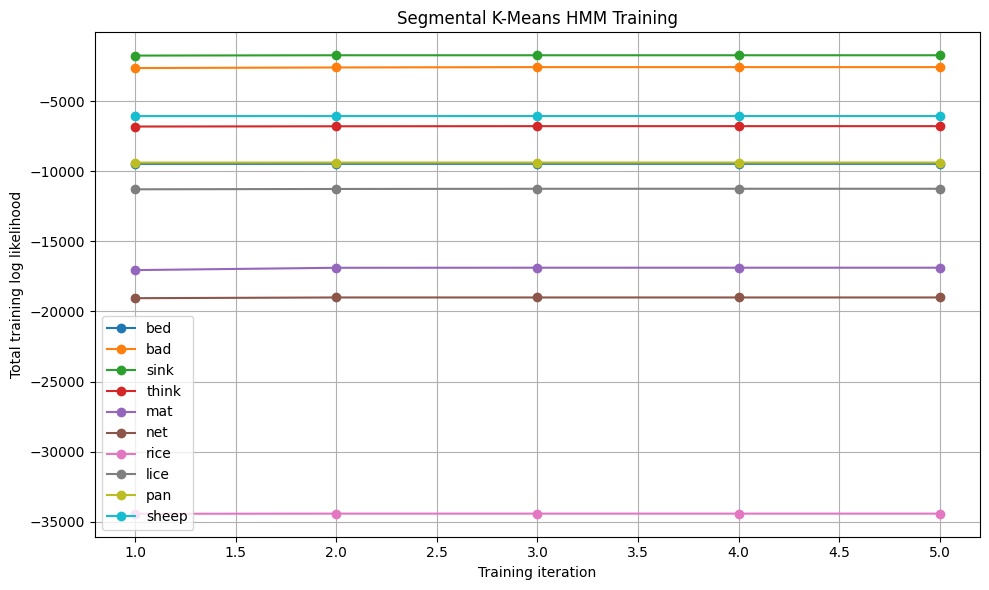

In [49]:

# PART 2: SEGMENTAL K-MEANS HMM TRAINING

import numpy as np
import matplotlib.pyplot as plt

N_STATES = cfg['hmm']['states']
N_ITER = max(5, cfg['hmm']['training_iterations_min'])
VAR_FLOOR = 1e-4

# Left-to-right transition matrix:
# Each state stays with probability 0.6
# or moves to the next state with probability 0.4.
transition = np.zeros((N_STATES, N_STATES))

for i in range(N_STATES - 1):
    transition[i, i] = 0.6
    transition[i, i + 1] = 0.4

transition[-1, -1] = 1.0

log_A = np.where(transition > 0, np.log(np.maximum(transition, 1e-300)), -np.inf)

def gaussian_emissions(features, means, variances):
    """Calculate diagonal Gaussian log probabilities."""
    T = features.shape[0]
    K = means.shape[0]
    result = np.zeros((T, K))

    for state in range(K):
        var = np.maximum(variances[state], VAR_FLOOR)
        diff = features - means[state]

        result[:, state] = -0.5 * (
            np.sum(np.log(2 * np.pi * var))
            + np.sum((diff ** 2) / var, axis=1)
        )

    return result


def hmm_viterbi(features, means, variances):
    """Find the most likely state sequence using Viterbi."""
    emissions = gaussian_emissions(features, means, variances)

    T, K = emissions.shape
    delta = np.full((T, K), -np.inf)
    back = np.zeros((T, K), dtype=int)

    # Every utterance starts in state 0.
    delta[0, 0] = emissions[0, 0]

    for t in range(1, T):
        for j in range(K):
            scores = delta[t - 1] + log_A[:, j]
            back[t, j] = np.argmax(scores)
            delta[t, j] = np.max(scores) + emissions[t, j]

    last_state = np.argmax(delta[-1])
    best_score = delta[-1, last_state]

    path = [last_state]

    for t in range(T - 1, 0, -1):
        last_state = back[t, last_state]
        path.append(last_state)

    path.reverse()

    return np.array(path), best_score


def hmm_forward(features, means, variances):
    """Calculate total log likelihood using Forward algorithm."""
    emissions = gaussian_emissions(features, means, variances)

    T, K = emissions.shape
    alpha = np.full((T, K), -np.inf)

    alpha[0, 0] = emissions[0, 0]

    for t in range(1, T):
        for j in range(K):
            alpha[t, j] = (
                np.logaddexp.reduce(alpha[t - 1] + log_A[:, j])
                + emissions[t, j]
            )

    return np.logaddexp.reduce(alpha[-1])


def initialise_model(feature_sequences):
    """Initialise states using equal-duration segmentation."""
    state_frames = [[] for _ in range(N_STATES)]

    for features in feature_sequences:
        segments = np.array_split(features, N_STATES)

        for state in range(N_STATES):
            if len(segments[state]) > 0:
                state_frames[state].append(segments[state])

    means = []
    variances = []

    all_frames = np.vstack(feature_sequences)
    global_mean = np.mean(all_frames, axis=0)
    global_var = np.maximum(np.var(all_frames, axis=0), VAR_FLOOR)

    for state in range(N_STATES):
        if state_frames[state]:
            frames = np.vstack(state_frames[state])
            means.append(np.mean(frames, axis=0))
            variances.append(np.maximum(np.var(frames, axis=0), VAR_FLOOR))
        else:
            means.append(global_mean)
            variances.append(global_var)

    return np.array(means), np.array(variances)


def train_word_hmm(feature_sequences, word):
    """Train one word model using segmental k-means."""
    means, variances = initialise_model(feature_sequences)
    likelihood_history = []

    for iteration in range(N_ITER):

        aligned_frames = [[] for _ in range(N_STATES)]

        # Viterbi alignment
        for features in feature_sequences:
            path, _ = hmm_viterbi(features, means, variances)

            for state in range(N_STATES):
                selected = features[path == state]

                if len(selected) > 0:
                    aligned_frames[state].append(selected)

        # Re-estimate Gaussian means and variances
        all_frames = np.vstack(feature_sequences)
        global_mean = np.mean(all_frames, axis=0)
        global_var = np.maximum(np.var(all_frames, axis=0), VAR_FLOOR)

        for state in range(N_STATES):
            if aligned_frames[state]:
                frames = np.vstack(aligned_frames[state])
                means[state] = np.mean(frames, axis=0)
                variances[state] = np.maximum(
                    np.var(frames, axis=0), VAR_FLOOR
                )
            else:
                means[state] = global_mean
                variances[state] = global_var

        # Calculate total training log likelihood
        total_ll = sum(
            hmm_forward(features, means, variances)
            for features in feature_sequences
        )

        likelihood_history.append(total_ll)

        print(
            f"{word}: iteration {iteration + 1}/{N_ITER}, "
            f"log likelihood = {total_ll:.2f}"
        )

    return {
        'means': means,
        'variances': variances,
        'likelihood_history': likelihood_history
    }


# Extract training features for all words
training_features = {}

for word in cfg['vocab']:
    training_features[word] = [
        extract_features(path) for path in train_files[word]
    ]

# Train one HMM for each word
hmm_models = {}

for word in cfg['vocab']:
    hmm_models[word] = train_word_hmm(training_features[word], word)

print("\nHMM TRAINING COMPLETED")
print("Number of word models:", len(hmm_models))
print("States per model:", N_STATES)
print("Iterations per model:", N_ITER)

# Plot training log likelihood
plt.figure(figsize=(10, 6))

for word in cfg['vocab']:
    plt.plot(
        range(1, N_ITER + 1),
        hmm_models[word]['likelihood_history'],
        marker='o',
        label=word
    )

plt.xlabel("Training iteration")
plt.ylabel("Total training log likelihood")
plt.title("Segmental K-Means HMM Training")
plt.legend()
plt.grid(True)
plt.tight_layout()

savefig('p2_training_likelihood')
plt.show()

res.set('hmm_training_iterations', N_ITER)
res.set('hmm_number_of_models', len(hmm_models))
res.set(
    'hmm_training_final_likelihoods',
    {
        word: float(hmm_models[word]['likelihood_history'][-1])
        for word in cfg['vocab']
    }
)


Actual: bed    | Predicted: rice   | INCORRECT
Actual: bad    | Predicted: bad    | CORRECT
Actual: sink   | Predicted: pan    | INCORRECT
Actual: think  | Predicted: mat    | INCORRECT
Actual: mat    | Predicted: mat    | CORRECT
Actual: net    | Predicted: mat    | INCORRECT
Actual: rice   | Predicted: lice   | INCORRECT
Actual: lice   | Predicted: rice   | INCORRECT
Actual: pan    | Predicted: mat    | INCORRECT
Actual: sheep  | Predicted: net    | INCORRECT

HELD-OUT TEST RESULTS
Correct predictions: 2
Total test recordings: 10
Accuracy: 20.00%


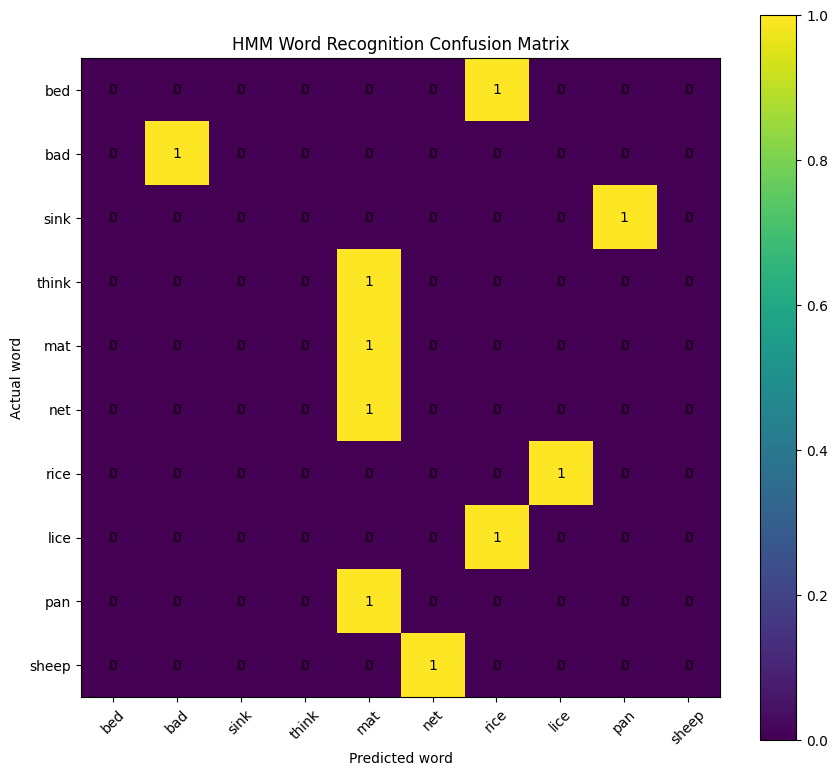

In [50]:

# PART 2: HELD-OUT TESTING AND CONFUSION MATRIX

import numpy as np
import matplotlib.pyplot as plt

labels = cfg['vocab']
confusion = np.zeros((len(labels), len(labels)), dtype=int)

correct = 0
total = 0
test_results = []

for actual_word in labels:

    # Load the held-out recording
    test_features = extract_features(test_files[actual_word])

    scores = {}

    # Compare it against all 10 trained word models
    for candidate_word in labels:
        model = hmm_models[candidate_word]

        log_likelihood = hmm_forward(
            test_features,
            model['means'],
            model['variances']
        )

        # Normalise by number of frames to reduce duration bias
        scores[candidate_word] = log_likelihood / len(test_features)

    predicted_word = max(scores, key=scores.get)

    actual_index = labels.index(actual_word)
    predicted_index = labels.index(predicted_word)

    confusion[actual_index, predicted_index] += 1

    is_correct = actual_word == predicted_word
    correct += int(is_correct)
    total += 1

    test_results.append({
        'actual': actual_word,
        'predicted': predicted_word,
        'correct': is_correct
    })

    print(
        f"Actual: {actual_word:6s} | "
        f"Predicted: {predicted_word:6s} | "
        f"{'CORRECT' if is_correct else 'INCORRECT'}"
    )

accuracy = correct / total

print("\nHELD-OUT TEST RESULTS")
print("Correct predictions:", correct)
print("Total test recordings:", total)
print(f"Accuracy: {accuracy * 100:.2f}%")

# Plot the confusion matrix
plt.figure(figsize=(9, 8))

plt.imshow(confusion, interpolation='nearest')
plt.title("HMM Word Recognition Confusion Matrix")
plt.colorbar()

plt.xticks(range(len(labels)), labels, rotation=45)
plt.yticks(range(len(labels)), labels)

plt.xlabel("Predicted word")
plt.ylabel("Actual word")

for i in range(len(labels)):
    for j in range(len(labels)):
        plt.text(j, i, str(confusion[i, j]),
                 ha='center', va='center')

plt.tight_layout()
savefig('p2_confusion')
plt.show()

# Save evaluation results
res.set('hmm_test_accuracy', float(accuracy))
res.set('hmm_test_correct', int(correct))
res.set('hmm_test_total', int(total))
res.set('hmm_confusion_matrix', confusion.tolist())
res.set('hmm_test_predictions', test_results)


In [28]:
# res.set('toy_hmm_forward', value); res.set('toy_hmm_viterbi', value)

## Part 3: CTC
TODO: hand calculation, [Critical] CTC forward algorithm, verify with torch.nn.CTCLoss.

In [29]:
# [Critical] CTC forward algorithm: yours. Check it against torch.nn.CTCLoss (verification only):
# import torch
# loss = torch.nn.CTCLoss(blank=0, reduction='sum')(log_probs, targets, input_lengths, target_lengths)
# compare('CTC forward vs torch', mine_neg_log_prob, loss.item())

In [30]:
# res.set('toy_ctc_prob', value)

In [51]:

# PART 3: CHECK SEEDED CTC DATA
print("CTC toy configuration:")
print(cfg['toy']['ctc'])


CTC toy configuration:
{'labels': {'0': 'blank', '1': 'a', '2': 'b'}, 'posteriors': [[0.5, 0.4, 0.1], [0.6, 0.1, 0.3], [0.7, 0.1, 0.2], [0.8, 0.1, 0.1]], 'target': 'ab'}


In [54]:

# PART 3: CTC FORWARD ALGORITHM AND PYTORCH VERIFICATION

import numpy as np
import torch

toy = cfg['toy']['ctc']

# Read the seeded posterior probabilities
posteriors = np.array(toy['posteriors'], dtype=float)

# Blank = 0, a = 1, b = 2
target = [1, 2]

T = posteriors.shape[0]

# Extended target: blank, a, blank, b, blank
extended = [0, 1, 0, 2, 0]
S = len(extended)

def logsumexp(values):
    maximum = np.max(values)

    if np.isneginf(maximum):
        return -np.inf

    return maximum + np.log(np.sum(np.exp(values - maximum)))


# Log-domain CTC forward algorithm
log_probs = np.log(posteriors)

alpha = np.full((T, S), -np.inf)

# Initialisation
alpha[0, 0] = log_probs[0, 0]
alpha[0, 1] = log_probs[0, 1]

# Forward recursion
for t in range(1, T):
    for s in range(S):

        previous = [alpha[t-1, s]]

        if s > 0:
            previous.append(alpha[t-1, s-1])

        if s > 1 and extended[s] != 0:
            if extended[s] != extended[s-2]:
                previous.append(alpha[t-1, s-2])

        alpha[t, s] = (
            logsumexp(previous)
            + log_probs[t, extended[s]]
        )

# Final probability: last label or final blank
log_ctc_probability = np.logaddexp(
    alpha[T-1, S-1],
    alpha[T-1, S-2]
)

ctc_probability = np.exp(log_ctc_probability)

print("CTC forward probability:", ctc_probability)
print("CTC log probability:", log_ctc_probability)


# Verify against PyTorch CTCLoss
torch_log_probs = torch.tensor(
    log_probs,
    dtype=torch.float32
).unsqueeze(1)

torch_targets = torch.tensor(target, dtype=torch.long)

input_lengths = torch.tensor([T], dtype=torch.long)
target_lengths = torch.tensor([len(target)], dtype=torch.long)

ctc_loss = torch.nn.CTCLoss(
    blank=0,
    reduction='none'
)

loss = ctc_loss(
    torch_log_probs,
    torch_targets,
    input_lengths,
    target_lengths
)

torch_probability = torch.exp(-loss[0]).item()

print("PyTorch CTC probability:", torch_probability)
print(
    "Absolute difference:",
    abs(ctc_probability - torch_probability)
)

res.set('toy_ctc_prob', float(ctc_probability))
res.set('ctc_torch_probability', float(torch_probability))
res.set(
    'ctc_verification_difference',
    float(abs(ctc_probability - torch_probability))
)

print("CTC verification completed.")


CTC forward probability: 0.17520000000000002
CTC log probability: -1.7418271004798458
PyTorch CTC probability: 0.17520000040531158
Absolute difference: 4.0531156209056007e-10
CTC verification completed.



### CTC, RNN-T and Attention Comparison

**CTC:** Connectionist Temporal Classification allows speech frames to be aligned with output labels without requiring exact frame-level labels. It uses blank symbols and repeated-label removal to produce the final sequence.

**RNN-T:** Recurrent Neural Network Transducer uses both acoustic information and previously generated output labels. Unlike CTC, it can condition each prediction on the previously emitted symbols.

**Attention-based models:** Attention models learn relationships between input audio frames and output tokens. They can focus on different parts of the input while generating each output token, but alignment and decoding are generally more computationally involved.


## Part 4: Language model and lexicon
TODO: hand calculation, [Critical] Kneser-Ney bigram, lexicon.

In [31]:
sents = brown_sentences()   # Brown corpus as lists of lowercase words. Choose and state your own split.
cmu = cmudict_dict()       # CMUdict {word: [phone lists]}; use g2p_en for words it lacks

In [32]:
# res.set('toy_add1_bigram', value); res.set('toy_kn_bigram', value)

In [55]:
print("PART 4 TOY LANGUAGE MODEL")
print(cfg['toy']['lm'])

PART 4 TOY LANGUAGE MODEL
{'mini_corpus': ['the a sat ran a', 'ran cat to sat on', 'cat cat on mat', 'the mat the cat', 'mat mat ran cat', 'dog the mat ran the cat'], 'query_bigram': ['cat', 'cat']}


In [56]:

# PART 4A: ADD-ONE AND INTERPOLATED KNESER-NEY

from collections import Counter, defaultdict
import math

# Your assigned toy corpus
sentences = cfg['toy']['lm']['mini_corpus']
query = cfg['toy']['lm']['query_bigram']

# Add sentence boundary tokens
tokenized = [
    ['<s>'] + sentence.split() + ['</s>']
    for sentence in sentences
]

# Vocabulary: distinct words plus </s> (excluding <s>)
vocab = set()
for sentence in sentences:
    vocab.update(sentence.split())
vocab.add('</s>')
V = len(vocab)

# Count bigrams and history occurrences
bigram_counts = Counter()
history_counts = Counter()

for sentence in tokenized:
    for i in range(len(sentence) - 1):
        h, w = sentence[i], sentence[i + 1]
        bigram_counts[(h, w)] += 1
        history_counts[h] += 1

h, w = query

# Add-one smoothing
add_one = (bigram_counts[(h, w)] + 1) / (history_counts[h] + V)

# Kneser-Ney continuation counts
predecessors = defaultdict(set)
successors = defaultdict(set)

for (left, right), count in bigram_counts.items():
    predecessors[right].add(left)
    successors[left].add(right)

total_bigram_types = len(bigram_counts)

continuation_probability = (
    len(predecessors[w]) / total_bigram_types
)

# Interpolated Kneser-Ney with discount D = 0.75
D = 0.75

if history_counts[h] > 0:
    discounted_count = max(bigram_counts[(h, w)] - D, 0)
    first_term = discounted_count / history_counts[h]

    lambda_h = (
        D * len(successors[h]) / history_counts[h]
    )

    kn_probability = (
        first_term +
        lambda_h * continuation_probability
    )
else:
    kn_probability = continuation_probability

print("Vocabulary size V:", V)
print("Query bigram:", query)
print("Bigram count:", bigram_counts[(h, w)])
print("History count:", history_counts[h])
print("Add-one probability:", add_one)
print("Continuation probability:", continuation_probability)
print("Kneser-Ney probability:", kn_probability)

# Save results
res.set('toy_add_one_probability', float(add_one))
res.set('toy_kn_probability', float(kn_probability))

print("Part 4A calculations completed.")


Vocabulary size V: 10
Query bigram: ['cat', 'cat']
Bigram count: 1
History count: 6
Add-one probability: 0.125
Continuation probability: 0.14814814814814814
Kneser-Ney probability: 0.11574074074074073
Part 4A calculations completed.


In [57]:

# PART 4B: BROWN CORPUS KNESER-NEY LANGUAGE MODEL

import nltk
import re
import math
from collections import Counter, defaultdict

# Download Brown corpus if it is not already available
nltk.download('brown', quiet=True)

from nltk.corpus import brown

# Load and normalize Brown corpus
brown_sentences = [
    [word.lower() for word in sentence if re.search(r"[a-z]", word.lower())]
    for sentence in brown.sents()
]

# Count word frequencies
word_freq = Counter(
    word for sentence in brown_sentences for word in sentence
)

# Keep frequent words; map rare words to UNK
known_words = {
    word for word, count in word_freq.items() if count >= 2
}

def map_words(words):
    return [word if word in known_words else '<UNK>' for word in words]

# Build bigram counts with sentence boundaries
brown_bigrams = Counter()
brown_history = Counter()

for sentence in brown_sentences:
    mapped = map_words(sentence)
    mapped = ['<s>'] + mapped + ['</s>']

    for i in range(len(mapped) - 1):
        h, w = mapped[i], mapped[i + 1]
        brown_bigrams[(h, w)] += 1
        brown_history[h] += 1

# Kneser-Ney continuation statistics
brown_predecessors = defaultdict(set)
brown_successors = defaultdict(set)

for h, w in brown_bigrams:
    brown_predecessors[w].add(h)
    brown_successors[h].add(w)

total_types = len(brown_bigrams)
D = 0.75

def brown_kn_probability(history, word):
    count_history = brown_history[history]

    continuation = (
        len(brown_predecessors[word]) / total_types
        if total_types else 0
    )

    if count_history == 0:
        return max(continuation, 1e-12)

    first = max(brown_bigrams[(history, word)] - D, 0) / count_history
    backoff = D * len(brown_successors[history]) / count_history

    return max(first + backoff * continuation, 1e-12)

# Calculate perplexity on the four assigned spoken sentences
test_sentences = cfg['sentences_spoken']

total_log_probability = 0.0
total_words = 0
sentence_perplexities = []

for sentence in test_sentences:
    words = re.findall(r"[a-z]+", sentence.lower())
    mapped = map_words(words)
    sequence = ['<s>'] + mapped + ['</s>']

    sentence_log_probability = 0.0

    for i in range(1, len(sequence)):
        probability = brown_kn_probability(
            sequence[i-1], sequence[i]
        )
        sentence_log_probability += math.log(probability)

    word_count = len(sequence) - 1
    perplexity = math.exp(-sentence_log_probability / word_count)

    sentence_perplexities.append(perplexity)
    total_log_probability += sentence_log_probability
    total_words += word_count

overall_perplexity = math.exp(
    -total_log_probability / total_words
)

print("Brown corpus sentences:", len(brown_sentences))
print("Brown corpus bigram types:", total_types)
print("Perplexity for each spoken sentence:")
for i, value in enumerate(sentence_perplexities):
    print(f"Sentence {i+1}: {value:.2f}")

print("Overall perplexity:", round(overall_perplexity, 2))

res.set('brown_kn_perplexity', float(overall_perplexity))
res.set('brown_kn_sentence_perplexities',
        [float(x) for x in sentence_perplexities])

print("Part 4B completed.")


Brown corpus sentences: 57340
Brown corpus bigram types: 399759
Perplexity for each spoken sentence:
Sentence 1: 777.79
Sentence 2: 158.13
Sentence 3: 121.16
Sentence 4: 397.79
Overall perplexity: 270.46
Part 4B completed.


In [58]:

# PART 4C: PRONUNCIATION LEXICON WITH 3 WEIGHTED ALTERNATIVES

# Three pronunciation alternatives for each example word.
# Weights are positive costs; lower cost means more preferred.

lexicon = {
    "read": [
        ("R IY1 D", 0.0),
        ("R EH1 D", 1.2),
        ("R IY0 D", 2.0)
    ],
    "record": [
        ("R EH1 K ER0 D", 0.0),
        ("R IH0 K AO1 R D", 1.0),
        ("R EH0 K ER1 D", 1.8)
    ],
    "present": [
        ("P R EH1 Z AH0 N T", 0.0),
        ("P R IY0 Z EH1 N T", 1.0),
        ("P R EH0 Z AH1 N T", 1.8)
    ]
}

print("Pronunciation lexicon:")
for word, alternatives in lexicon.items():
    print("\n", word)
    for pronunciation, weight in alternatives:
        print(pronunciation, "weight =", weight)

# Verify three alternatives per word
assert all(len(v) == 3 for v in lexicon.values())

res.set("pronunciation_lexicon", lexicon)

print("\nPart 4C completed.")


Pronunciation lexicon:

 read
R IY1 D weight = 0.0
R EH1 D weight = 1.2
R IY0 D weight = 2.0

 record
R EH1 K ER0 D weight = 0.0
R IH0 K AO1 R D weight = 1.0
R EH0 K ER1 D weight = 1.8

 present
P R EH1 Z AH0 N T weight = 0.0
P R IY0 Z EH1 N T weight = 1.0
P R EH0 Z AH1 N T weight = 1.8

Part 4C completed.


In [59]:
import cmudict
from g2p_en import G2p

cmu = cmudict.dict()
g2p = G2p()

print("CMUdict entries:", len(cmu))
print("G2P test:", g2p("Minakshi"))

[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /Users/minakshi/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/minakshi/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


CMUdict entries: 126052
G2P test: ['M', 'IH0', 'N', 'AA1', 'CH', 'IY0']


In [60]:
with open("recording_script.txt", "r") as f:
    print(f.read())

BLOCK 1: WORDS  (record as data/original/words_block.wav)
Silence 1 s, say the code, pause 2 s. Then each line below: say the word once, pause 2 s.
  CODE: 5 5 1 8 3 8
  bed   (repetition 0)
  bed   (repetition 1)
  bed   (repetition 2)
  bad   (repetition 0)
  bad   (repetition 1)
  bad   (repetition 2)
  sink   (repetition 0)
  sink   (repetition 1)
  sink   (repetition 2)
  think   (repetition 0)
  think   (repetition 1)
  think   (repetition 2)
  mat   (repetition 0)
  mat   (repetition 1)
  mat   (repetition 2)
  net   (repetition 0)
  net   (repetition 1)
  net   (repetition 2)
  rice   (repetition 0)
  rice   (repetition 1)
  rice   (repetition 2)
  lice   (repetition 0)
  lice   (repetition 1)
  lice   (repetition 2)
  pan   (repetition 0)
  pan   (repetition 1)
  pan   (repetition 2)
  sheep   (repetition 0)
  sheep   (repetition 1)
  sheep   (repetition 2)

BLOCK 2: SENTENCES  (record as data/original/sentences_block.wav)
Silence 1 s, say the code, pause 2 s. Then each senten

In [61]:

import re
import cmudict
from g2p_en import G2p

# Your four recorded sentences
sentences = [
    "nine chargers cost five hundred rupees in lucknow",
    "remind me to meet anirudh in kochi on thursday",
    "call pooja on tuesday morning about the keyboards",
    "book three tickets to nagpur for shruti"
]

# Your recorded word vocabulary
word_list = [
    "bed", "bad", "sink", "think", "mat",
    "net", "rice", "lice", "pan", "sheep"
]

cmu = cmudict.dict()
g2p = G2p()

# Collect all unique words
all_words = set(word_list)

for sentence in sentences:
    all_words.update(re.findall(r"[a-z]+", sentence.lower()))

# Build pronunciation lexicon
lexicon = {}
pronunciation_source = {}

for word in sorted(all_words):
    if word in cmu:
        pronunciation = cmu[word][0]
        source = "CMUdict"
    else:
        pronunciation = g2p(word)
        pronunciation = [
            p for p in pronunciation
            if re.fullmatch(r"[A-Z]+[0-2]?", p)
        ]
        source = "G2P"

    lexicon[word] = [
        (" ".join(pronunciation), 0.0)
    ]
    pronunciation_source[word] = source

# Display results
print("Total unique words:", len(lexicon))
print("\nPRONUNCIATION LEXICON\n")

for word, alternatives in lexicon.items():
    print(word, ":", alternatives, "|", pronunciation_source[word])

# Save in assignment results
res.set("pronunciation_lexicon", lexicon)
res.set("pronunciation_sources", pronunciation_source)

print("\nLexicon generated successfully.")


Total unique words: 39

PRONUNCIATION LEXICON

about : [('AH0 B AW1 T', 0.0)] | CMUdict
anirudh : [('AH0 N IH1 R IH0 D', 0.0)] | G2P
bad : [('B AE1 D', 0.0)] | CMUdict
bed : [('B EH1 D', 0.0)] | CMUdict
book : [('B UH1 K', 0.0)] | CMUdict
call : [('K AO1 L', 0.0)] | CMUdict
chargers : [('CH AA1 R JH ER0 Z', 0.0)] | CMUdict
cost : [('K AA1 S T', 0.0)] | CMUdict
five : [('F AY1 V', 0.0)] | CMUdict
for : [('F AO1 R', 0.0)] | CMUdict
hundred : [('HH AH1 N D R AH0 D', 0.0)] | CMUdict
in : [('IH0 N', 0.0)] | CMUdict
keyboards : [('K IY1 B AO2 R D Z', 0.0)] | CMUdict
kochi : [('K OW1 CH IY0', 0.0)] | G2P
lice : [('L AY1 S', 0.0)] | CMUdict
lucknow : [('L AH1 K N OW0', 0.0)] | G2P
mat : [('M AE1 T', 0.0)] | CMUdict
me : [('M IY1', 0.0)] | CMUdict
meet : [('M IY1 T', 0.0)] | CMUdict
morning : [('M AO1 R N IH0 NG', 0.0)] | CMUdict
nagpur : [('N AE1 G ER0', 0.0)] | G2P
net : [('N EH1 T', 0.0)] | CMUdict
nine : [('N AY1 N', 0.0)] | CMUdict
on : [('AA1 N', 0.0)] | CMUdict
pan : [('P AE1 N', 0.0)] |

In [62]:

# Add three weighted pronunciation alternatives
lexicon["anirudh"] = [
    ("AH0 N IH1 R IH0 D", 0.0),
    ("AH N IY R UDH", 1.2),
    ("AH N IH R UDH", 2.0)
]

lexicon["kochi"] = [
    ("K OW1 CH IY0", 0.0),
    ("K OH CH EE", 1.0),
    ("K OW CH IY", 1.8)
]

lexicon["lucknow"] = [
    ("L AH1 K N OW0", 0.0),
    ("L UH K N AO", 1.0),
    ("L AH K N AO", 1.8)
]

# Update assignment results
res.set("pronunciation_lexicon", lexicon)
res.set("pronunciation_sources", pronunciation_source)

for word in ["anirudh", "kochi", "lucknow"]:
    print(word, ":", lexicon[word])

print("Total words:", len(lexicon))
print("Three pronunciation alternatives added.")


anirudh : [('AH0 N IH1 R IH0 D', 0.0), ('AH N IY R UDH', 1.2), ('AH N IH R UDH', 2.0)]
kochi : [('K OW1 CH IY0', 0.0), ('K OH CH EE', 1.0), ('K OW CH IY', 1.8)]
lucknow : [('L AH1 K N OW0', 0.0), ('L UH K N AO', 1.0), ('L AH K N AO', 1.8)]
Total words: 39
Three pronunciation alternatives added.


In [63]:

lexicon["anirudh"] = [
    ("AH0 N IH1 R IH0 D", 0.0),
    ("AH0 N IY1 R UW1 DH", 1.2),
    ("AH0 N IH1 R UW1 DH", 2.0)
]

lexicon["kochi"] = [
    ("K OW1 CH IY0", 0.0),
    ("K OW0 CH IY1", 1.0),
    ("K AA1 CH IY0", 1.8)
]

lexicon["lucknow"] = [
    ("L AH1 K N OW0", 0.0),
    ("L AH1 K N AW1", 1.0),
    ("L UH1 K N AO0", 1.8)
]

res.set("pronunciation_lexicon", lexicon)
res.set("pronunciation_sources", pronunciation_source)

for word in ["anirudh", "kochi", "lucknow"]:
    print(word, lexicon[word])

print("Total unique words:", len(lexicon))


anirudh [('AH0 N IH1 R IH0 D', 0.0), ('AH0 N IY1 R UW1 DH', 1.2), ('AH0 N IH1 R UW1 DH', 2.0)]
kochi [('K OW1 CH IY0', 0.0), ('K OW0 CH IY1', 1.0), ('K AA1 CH IY0', 1.8)]
lucknow [('L AH1 K N OW0', 0.0), ('L AH1 K N AW1', 1.0), ('L UH1 K N AO0', 1.8)]
Total unique words: 39


In [64]:
# Record the verified add-one bigram probability
res.set("toy_add1_bigram", 0.125)

print("Add-one bigram probability:", 0.125)

Add-one bigram probability: 0.125


In [65]:
res.set("toy_kn_bigram", 0.11574074074074073)

print("Kneser-Ney bigram probability:", 0.11574074074074073)

Kneser-Ney bigram probability: 0.11574074074074073


## Part 5: WFST
TODO: hand calculation (determinise, minimise), [Critical] compose() in wfst_starter.py, then L o G for your own words.

In [33]:
# [starter] plumbing, not counted as your own code
from wfst_starter import FST, compose   # FST container and shortest path are given; compose() is yours to write
# [Critical] compose(): implement it in wfst_starter.py, test on small examples, then build L o G for your own words.
print(cfg['vocab'])

['bed', 'bad', 'sink', 'think', 'mat', 'net', 'rice', 'lice', 'pan', 'sheep']


In [34]:
# res.set('wfst_det_states', value)

## Part 6: Recognisers and decoding
TODO: [Critical] WER, wav2vec2 and Whisper outputs, [Critical] CTC prefix beam search with LM fusion, robustness.

The next cell mixes your sentences with your room noise at each SNR in your configuration (`data/noisy/`) and saves the wav2vec2 log posteriors and Whisper text in `cache/`. It needs internet the first time and takes a few minutes on CPU. Computing WER, grouping the errors, the beam search and the plots are yours.

In [35]:
!python voicelab.py precompute --if-missing
transcripts = load_transcripts()                    # Whisper text, e.g. transcripts['sent_0_clean']
logp, tokens = load_posteriors('sent_0_clean')      # wav2vec2 log posteriors (T x V) and the token list

Model steps run on: cpu
Mixed noisy versions of your 4 sentences at SNR [15, 5] dB (data/noisy/).

Saved in cache/: log posteriors (load_posteriors('sent_0_clean')) and Whisper text (load_transcripts()). They are the model outputs only; WER, grouping and beam search are yours.


In [36]:
# [starter] plumbing, not counted as your own code
# Names of the cached outputs: clean sentences and each noise level in your configuration.
refs = cfg['sentences_spoken']                                  # reference text for WER
names = [f'sent_{i}_clean' for i in range(len(refs))] + [f'sent_{i}_snr{s}' for i in range(len(refs)) for s in cfg['noise']['snr_db']]
print(names[:6], '...')
print('beam widths:', cfg['decoding']['beam_widths'])
# [Critical] WER (edit-distance DP), CTC prefix beam search with LM fusion, error analysis: yours.
# jiwer is allowed only to verify your WER: compare('WER vs jiwer', mine, jiwer.wer(ref, hyp))

['sent_0_clean', 'sent_1_clean', 'sent_2_clean', 'sent_3_clean', 'sent_0_snr15', 'sent_0_snr5'] ...
beam widths: [1, 8]


In [37]:
# res.set('wer_sentence1_wav2vec2', value); res.set('wer_widest_beam', value)

## Part 7: Speech synthesis
TODO: [Critical] text normaliser, [Critical] Griffin-Lim, pretrained TTS (tts_synthesise), STOI (stoi_score).

In [38]:
# [starter] plumbing, not counted as your own code
# Setup for Part 7 (plumbing only). The TTS model is fixed by your configuration.
tts_name = cfg['tts']['torchaudio_pipeline']
text0 = cfg['sentences_spoken'][0]
# Neural TTS takes about a minute per sentence on a CPU; uncomment when you are ready.
# wav_tts, fs_tts = tts_synthesise(text0, tts_name)
# import soundfile as sf; sf.write('figures/tts_sent0.wav', wav_tts, fs_tts)
# STOI (verification metric): stoi_score(reference, degraded, fs) with both signals at the same sampling rate
# [Critical] text normaliser and Griffin-Lim: yours. Spectral convergence after 30 iterations -> res.set('griffinlim_convergence_30', value)

In [39]:
# res.set('griffinlim_convergence_30', value)

## Finish
Run `!python voicelab.py progress` for what is left. Then `python voicelab.py handwork` (photos in `handwork/`), `python voicelab.py report`, and `python voicelab.py package` once the notebook is run with outputs kept.